# 04 — Tree models (FD001)

Random Forest and gradient boosting fit non-linear degradation patterns that the linear baseline cannot capture. Both models use the same rolling features and engine split as notebook 03.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from load_data import load_test, load_train
from features import FEATURES, add_rolling_features
from evaluation import mae, rmse, split_train_val, test_points, validation_points

## 1. Data

The split is by engine rather than by row, so cycles from one engine cannot appear on both sides. The validation and test points use the same fixed protocol as the linear baseline.

In [2]:
train = add_rolling_features(load_train())
test = add_rolling_features(load_test())
train_df, val_df = split_train_val(train)
val_pts = validation_points(val_df)
test_pts = test_points(test)

print("train_df:", len(train_df), "rows")
print("val_df:  ", len(val_df), "rows")
print("val_pts:", len(val_pts), "| test_pts:", len(test_pts))

train_df: 16390 rows
val_df:   4241 rows
val_pts: 100 | test_pts: 100


## 2. Two non-linear models

Random Forest averages many independently fitted trees, mainly reducing variance. Gradient boosting adds small trees in sequence, with each tree correcting the previous model, mainly reducing bias. Trees do not need scaling.

`early_stopping=False` prevents gradient boosting from making a random row holdout that could place cycles from the same engine on both sides.

In [3]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.33,
                           random_state=42, n_jobs=-1)
gb = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=200, max_depth=3,
                                   early_stopping=False, random_state=42)

models = {"random_forest": rf, "gradient_boosting": gb}
for model in models.values():
    model.fit(train_df[FEATURES], train_df["rul"])

val_pred = {name: model.predict(val_pts[FEATURES]) for name, model in models.items()}
test_pred = {name: model.predict(test_pts[FEATURES]) for name, model in models.items()}

## 3. Validation scores

These metrics are measured at the same 100 fixed validation points used by the linear models.

In [4]:
pd.DataFrame([
    {"model": name, "mae": mae(val_pts["rul"], pred), "rmse": rmse(val_pts["rul"], pred)}
    for name, pred in val_pred.items()
]).round(2)

,model,mae,rmse
0,random_forest,25.03,40.17
1,gradient_boosting,26.12,40.17


## 4. Fit check

Random Forest fits the training rows much better than validation, showing some overfitting. Gradient boosting has a smaller train-to-validation gap.

In [5]:
pd.DataFrame([
    {"model": name,
     "train_rmse": rmse(train_df["rul"], model.predict(train_df[FEATURES])),
     "val_rmse_all_rows": rmse(val_df["rul"], model.predict(val_df[FEATURES]))}
    for name, model in models.items()
]).round(2)

,model,train_rmse,val_rmse_all_rows
0,random_forest,21.15,42.62
1,gradient_boosting,29.66,43.02


## 5. Predicted versus actual

Each panel compares predictions with true RUL at the 100 validation points. The diagonal represents perfect predictions.

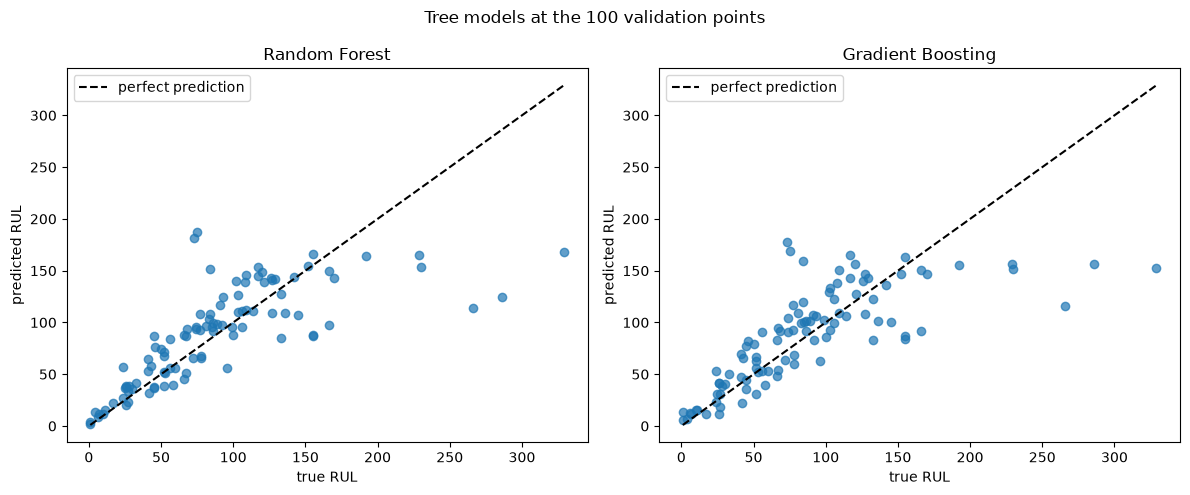

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
y = val_pts["rul"]
for ax, (name, pred) in zip(axes, val_pred.items()):
    ax.scatter(y, pred, alpha=0.7)
    lim = [min(y.min(), pred.min()), max(y.max(), pred.max())]
    ax.plot(lim, lim, "k--", label="perfect prediction")
    ax.set(xlabel="true RUL", ylabel="predicted RUL", title=name.replace("_", " ").title())
    ax.legend()
fig.suptitle("Tree models at the 100 validation points")
plt.tight_layout()
plt.show()

## 6. Feature importance

The Random Forest's feature importance shows what the model uses, not what causes failure. Correlated features can share credit, so importance is not causal evidence. `cycle` leads, followed by sensor rolling means.

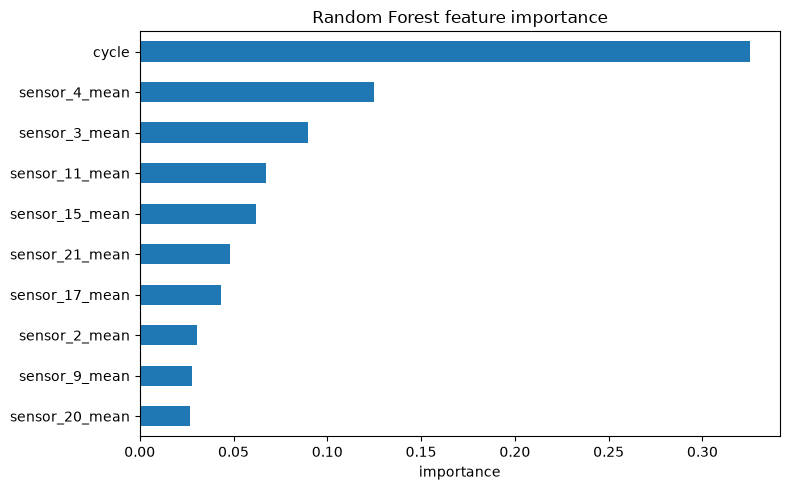

cycle             0.325
sensor_4_mean     0.125
sensor_3_mean     0.090
sensor_11_mean    0.067
sensor_15_mean    0.062
sensor_21_mean    0.048
sensor_17_mean    0.043
sensor_2_mean     0.031
sensor_9_mean     0.028
sensor_20_mean    0.027
dtype: float64

In [7]:
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
importance.head(10).sort_values().plot.barh(figsize=(8, 5), title="Random Forest feature importance")
plt.xlabel("importance")
plt.tight_layout()
plt.show()
importance.head(10).round(3)

## 7. Save predictions

There is no test scoring here. The next notebook compares the saved predictions with the test RUL answers.

In [8]:
val_out = val_pts[["engine_id", "cycle"]].copy()
test_out = test_pts[["engine_id"]].copy()
for name in models:
    val_out[name] = val_pred[name]
    test_out[name] = test_pred[name]

val_out.to_csv("../results/val_predictions_trees.csv", index=False)
test_out.to_csv("../results/test_predictions_trees.csv", index=False)
print("val:", val_out.shape, "| test:", test_out.shape)
test_out.head(3).round(2)

val: (100, 4) | test: (100, 3)


,engine_id,random_forest,gradient_boosting
30,1,166.04,164.49
79,2,154.59,157.63
205,3,51.96,58.25
